In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 


In [2]:
s = r"D:\MLtrial\archive\FuelConsumptionCo2.csv"
print(f"from URL {s} \n")
df = pd.read_csv(s)
# df.tail()
df.describe()

from URL D:\MLtrial\archive\FuelConsumptionCo2.csv 



,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [3]:
df = df.drop(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'TRANSMISSION', 'FUELTYPE'],axis=1)
df.corr()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
ENGINESIZE,1.000000,0.934011,0.832225,0.778746,0.819482,-0.808554,0.874154
CYLINDERS,0.934011,1.000000,0.796473,0.724594,0.776788,-0.770430,0.849685
FUELCONSUMPTION_CITY,0.832225,0.796473,1.000000,0.965718,0.995542,-0.935613,0.898039
FUELCONSUMPTION_HWY,0.778746,0.724594,0.965718,1.000000,0.985804,-0.893809,0.861748
FUELCONSUMPTION_COMB,0.819482,0.776788,0.995542,0.985804,1.000000,-0.927965,0.892129
FUELCONSUMPTION_COMB_MPG,-0.808554,-0.770430,-0.935613,-0.893809,-0.927965,1.000000,-0.906394
CO2EMISSIONS,0.874154,0.849685,0.898039,0.861748,0.892129,-0.906394,1.000000


In [4]:
df = df.drop(['CYLINDERS','FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB' ],axis=1)
df.head(9)

,ENGINESIZE,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2.0,33,196
1,2.4,29,221
2,1.5,48,136
3,3.5,25,255
4,3.5,27,244
5,3.5,28,230
6,3.5,28,232
7,3.7,25,255
8,3.7,24,267


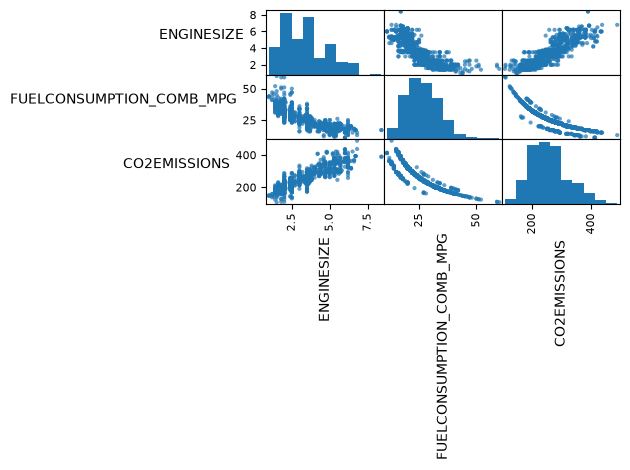

In [ ]:
axis = pd.plotting.scatter_matrix(df, alpha=0.7)
for ax in axis.flatten():
    ax.xaxis.label.set_rotation(90)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_ha('right')

plt.tight_layout()
plt.gcf().subplots_adjust(wspace=0, hspace=0)
plt.show()
# sns.pairplot(df)

### Determine features and target & Scale them:

In [15]:
X = df.iloc[: , [0,1]].to_numpy()
y = df.iloc[: , 2].to_numpy()


In [16]:
from sklearn import preprocessing
std_scalar = preprocessing.StandardScaler()
X_std = std_scalar.fit_transform(X)


In [39]:
pd.DataFrame(X_std).describe().round(2)

,0,1
count,1067.00,1067.00
mean,0.00,-0.00
std,1.00,1.00
min,-1.66,-2.07
25%,-0.95,-0.73
50%,0.04,-0.06
75%,0.67,0.61
max,3.57,4.50


In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_std, y, test_size=.2)


### Multilinear Regression model : 

In [22]:
class MultiLinearRegression : 
    def __init__(self, eta= .01, random_state= 42, n_iter = 660):
        self.eta = eta
        self.random_state = random_state
        self.n_iter = n_iter

    def fit(self, X,y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc = 0, scale= 1, size= 1 + X.shape[1])
        self.losses_ = []
        for _ in range(self.n_iter):
            y_pred = X.dot(self.w_[1:]) + self.w_[0]
            row_error = y - y_pred
            loss = (row_error **2).mean()
            grad_w = -2 * X.T.dot(row_error) / X.shape[0]
            grad_b = -2 * row_error.mean()
            self.w_[1:] -= grad_w * self.eta
            self.w_[0] -= grad_b * self.eta
            self.losses_.append(loss)
        return self
    def predict(self, X):
        return X.dot(self.w_[1:]) + self.w_[0]


        

### Training data : 

In [23]:
mreg = MultiLinearRegression(eta= 0.01, n_iter=660)
mreg.fit(X_train, y_train)

In [31]:
y_pred = mreg.predict(X_test)

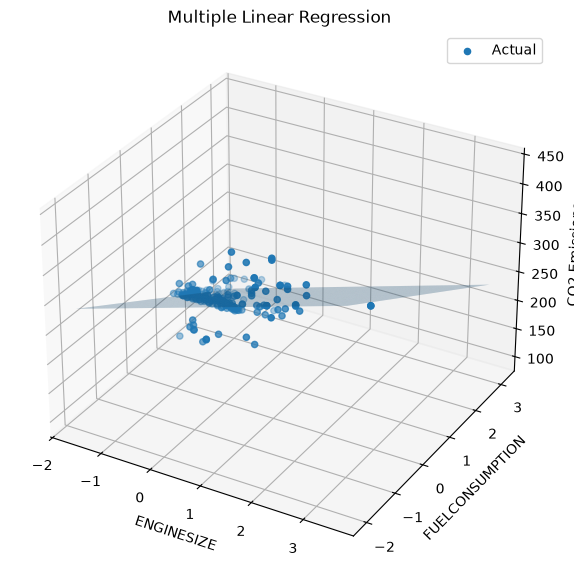

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Get the two features
X1 = X_test[:, 0]
X2 = X_test[:, 1]

# Actual target
Y = y_test

# Create grid for the plane
x1_surf, x2_surf = np.meshgrid(
    np.linspace(X1.min(), X1.max(), 50),
    np.linspace(X2.min(), X2.max(), 50)
)

# Regression plane
y_surf = (
    mreg.w_[0]
    + mreg.w_[1] * x1_surf
    + mreg.w_[2] * x2_surf
)

# Plot
fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection='3d')

# Actual data points
ax.scatter(
    X1,
    X2,
    Y,
    label='Actual'
)

# Regression plane
ax.plot_surface(
    x1_surf,
    x2_surf,
    y_surf,
    alpha=0.3
)

ax.set_xlabel('ENGINESIZE')
ax.set_ylabel('FUELCONSUMPTION')
ax.set_zlabel('CO2 Emissions')

ax.set_title('Multiple Linear Regression')

ax.legend()

plt.show()

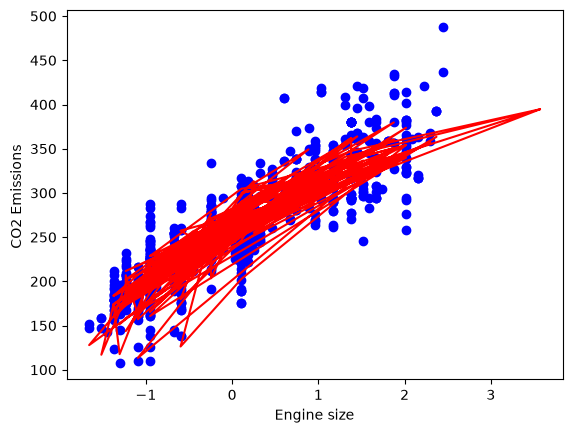

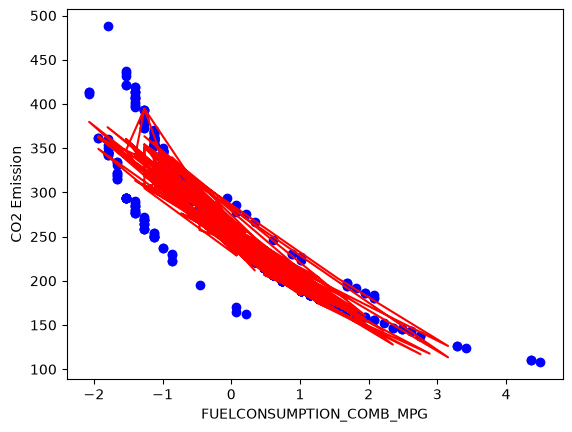

In [34]:
plt.scatter(X_train[: , 0], y_train,color= 'blue')
plt.plot(X_test[: , 0],y_pred, color='red')
plt.xlabel('Engine size')
plt.ylabel('CO2 Emissions ')
plt.show()

plt.scatter(X_train[:,1], y_train,  color='blue')
plt.plot(X_test[:, 1] ,y_pred, color='red')
plt.xlabel("FUELCONSUMPTION_COMB_MPG")
plt.ylabel("CO2 Emission")
plt.show()

### Multi Linear Regression with SKlearn :

In [40]:
from sklearn import linear_model
mreg_2 = linear_model.LinearRegression()
mreg_2.fit(X_train, y_train)
coef_ = mreg_2.coef_
intercept_ = mreg_2.intercept_
print(f"Coeffiecients : {coef_}")
print(f"intercept : {intercept_}")


Coeffiecients : [ 25.50125621 -36.67644207]
intercept : 256.14653209228817


In [41]:
means_ = std_scalar.mean_
std_devs = np.sqrt(std_scalar.var_)
coef_original = coef_ / std_devs
intercept_original = intercept_ - np.sum((means_ * coef_)/ std_devs)
print ('Coefficients: ', coef_original)
print ('Intercept: ', intercept_original)


Coefficients:  [18.01914243 -4.91298768]
Intercept:  325.7555043462574


### visualization :

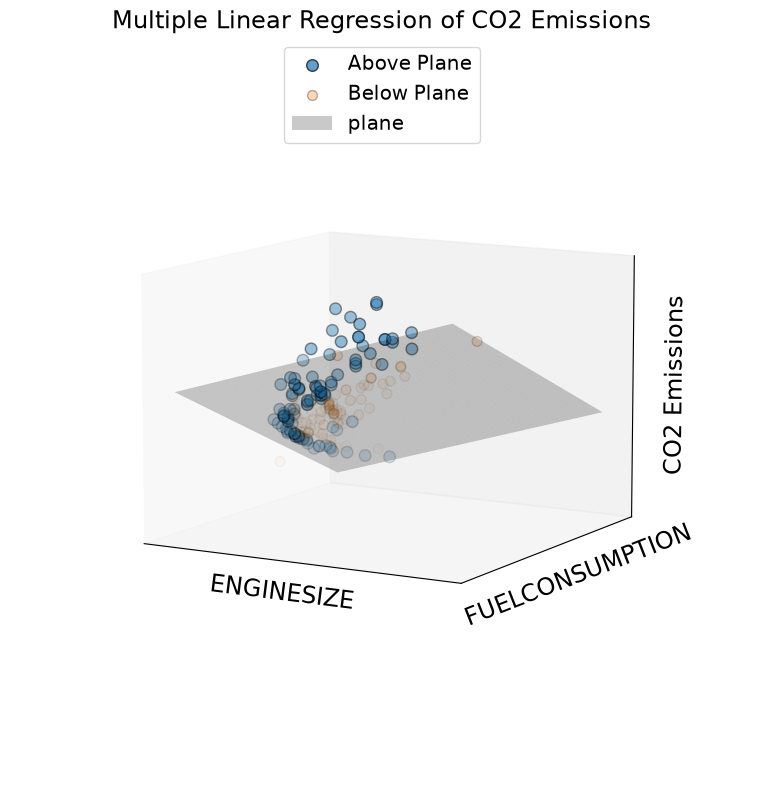

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure X1, X2, and y_test have compatible shapes for 3D plotting
X1 = X_test[:, 0] if X_test.ndim > 1 else X_test
X2 = X_test[:, 1] if X_test.ndim > 1 else np.zeros_like(X1)

# Create a mesh grid for plotting the regression plane
x1_surf, x2_surf = np.meshgrid(np.linspace(X1.min(), X1.max(), 100), 
                               np.linspace(X2.min(), X2.max(), 100))

y_surf = intercept_ +  coef_[0] * x1_surf  +  coef_[1] * x2_surf

# Predict y values using trained regression model to compare with actual y_test for above/below plane colors
y_pred = mreg_2.predict(X_test.reshape(-1, 1)) if X_test.ndim == 1 else mreg_2.predict(X_test)
above_plane = y_test >= y_pred
below_plane = y_test < y_pred
above_plane = above_plane[:]
below_plane = below_plane[:]

# Plotting
fig = plt.figure(figsize=(20, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the data points above and below the plane in different colors
ax.scatter(X1[above_plane], X2[above_plane], y_test[above_plane],  label="Above Plane",s=70,alpha=.7,ec='k')
ax.scatter(X1[below_plane], X2[below_plane], y_test[below_plane],  label="Below Plane",s=50,alpha=.3,ec='k')

# Plot the regression plane
ax.plot_surface(x1_surf, x2_surf, y_surf, color='k', alpha=0.21,label='plane')

# Set view and labels
ax.view_init(elev=10)

ax.legend(fontsize='x-large',loc='upper center')
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
ax.set_box_aspect(None, zoom=0.75)
ax.set_xlabel('ENGINESIZE', fontsize='xx-large')
ax.set_ylabel('FUELCONSUMPTION', fontsize='xx-large')
ax.set_zlabel('CO2 Emissions', fontsize='xx-large')
ax.set_title('Multiple Linear Regression of CO2 Emissions', fontsize='xx-large')
plt.tight_layout()
plt.show()


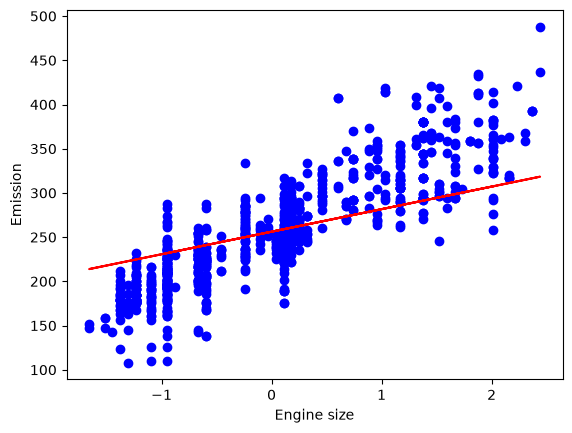

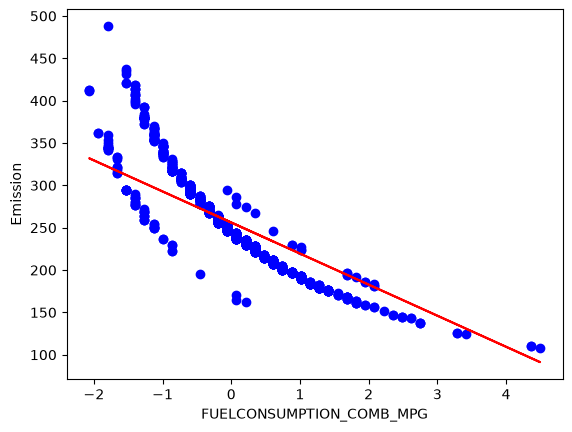

In [48]:
plt.scatter(X_train[:,0], y_train,  color='blue')
plt.plot(X_train[:,0], coef_[0] * X_train[:,0] + intercept_, '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.show()

plt.scatter(X_train[:,1], y_train,  color='blue')
plt.plot(X_train[:,1], coef_[1] * X_train[:,1] + intercept_, '-r')
plt.xlabel("FUELCONSUMPTION_COMB_MPG")
plt.ylabel("Emission")
plt.show()

In [49]:
X_train_1 = X_train[:,0]
regressor_1 = linear_model.LinearRegression()
regressor_1.fit(X_train_1.reshape(-1, 1), y_train)
coef_1 =  regressor_1.coef_
intercept_1 = regressor_1.intercept_
print ('Coefficients: ',coef_1)
print ('Intercept: ',intercept_1)

Coefficients:  [55.29282522]
Intercept:  256.2424254501409


Text(0, 0.5, 'Emission')

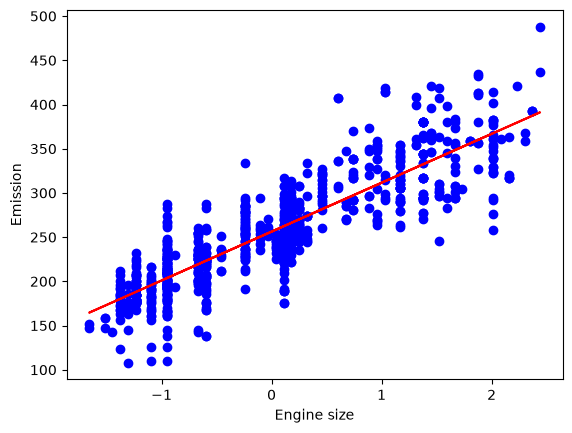

In [50]:
plt.scatter(X_train_1, y_train,  color='blue')
plt.plot(X_train_1, coef_1[0] * X_train_1 + intercept_1, '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")